# Keras Clasificación binaria

# 1.Importación librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Creación del modelo y carga de Librerías

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation,Dropout

import pandas as pd
import numpy as np

In [8]:
X_train = pd.read_csv('../data/processed/X_test_binario.csv')
y_train = pd.read_csv('../data/processed/Y_test_binario.csv')
X_test = pd.read_csv('../data/processed/X_test_binario.csv')
y_test = pd.read_csv('../data/processed/Y_test_binario.csv')

X_train.shape

(200, 61)

# 2. Entrenamiento del modelo

### 2.1. Uso del Early Stopping pero sin DropOut Layers

In [45]:
model = Sequential()
model.add(Dense(units=num_neuronas,activation='relu'))
model.add(Dense(units=int(np.round(num_neuronas / 2)), activation='relu'))
#model.add(Dense(units=np.round(num_neuronas/2),activation='relu')) SENTENCIA ORIGINAL
model.add(Dense(units=1,activation='sigmoid')) 
model.compile(loss='binary_crossentropy', optimizer='adam')

In [46]:
from tensorflow.keras.callbacks import EarlyStopping

In [47]:
early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=25)

In [48]:
model.fit(x=X_train, 
          y=y_train, 
          epochs=600,
          validation_data=(X_test, y_test), verbose=1,
          callbacks=[early_stop]
          )

Epoch 1/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - loss: 0.6501 - val_loss: 0.5939
Epoch 2/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5755 - val_loss: 0.5582
Epoch 3/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5524 - val_loss: 0.5414
Epoch 4/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5350 - val_loss: 0.5179
Epoch 5/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.5109 - val_loss: 0.4934
Epoch 6/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.4871 - val_loss: 0.4721
Epoch 7/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.4658 - val_loss: 0.4521
Epoch 8/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4460 - val_loss: 0.4330
Epoch 9/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4274 - val_loss: 0.4138
Epoch 10/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4087 - val_loss: 0.3952
Epoch 11/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.3905 - val_loss: 0.3779
Epoch 12/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3740 - val_lo

<Axes: >

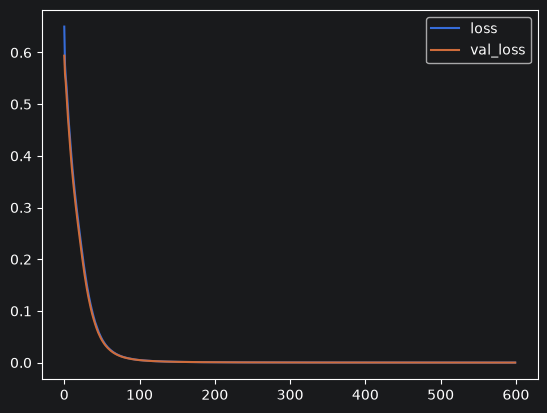

In [49]:
model_loss = pd.DataFrame(model.history.history)
model_loss.plot()

### 2.2. Modelo que emplea tanto Early Stopping así como DropOut Layers

In [115]:
from tensorflow.keras.layers import Dropout

In [131]:
model = Sequential()

model.add(Dense(units=num_neuronas,activation='relu'))
model.add(Dropout(0.5)) #la mitad de las neuronas en cada epoch para esta capa

# model.add(Dense(units=np.round(num_neuronas/2),activation='relu')) SENTENCIA ORIGINAL
model.add(Dense(units=int(np.round(num_neuronas / 2)), activation='relu'))
model.add(Dropout(0.5)) #la mitad de las neuronas en cada epoch para esta capa

model.add(Dense(units=1,activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam')

In [132]:
# CELDA ORIGINAL

model.fit(x=X_train,
          y=y_train, 
          epochs=600,
          validation_data=(X_test, y_test), verbose=1,
          callbacks=[early_stop]
          )

Epoch 1/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - loss: 0.7204 - val_loss: 0.6519
Epoch 2/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6652 - val_loss: 0.6254
Epoch 3/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.6709 - val_loss: 0.6092
Epoch 4/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.6253 - val_loss: 0.5988
Epoch 5/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6237 - val_loss: 0.5900
Epoch 6/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.6031 - val_loss: 0.5820
Epoch 7/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6745 - val_loss: 0.5749
Epoch 8/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6394 - val_loss: 0.5689
Epoch 9/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6201 - val_loss: 0.5620
Epoch 10/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5817 - val_loss: 0.5553
Epoch 11/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5868 - val_loss: 0.5468
Epoch 12/600
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5930 - val_l

<Axes: >

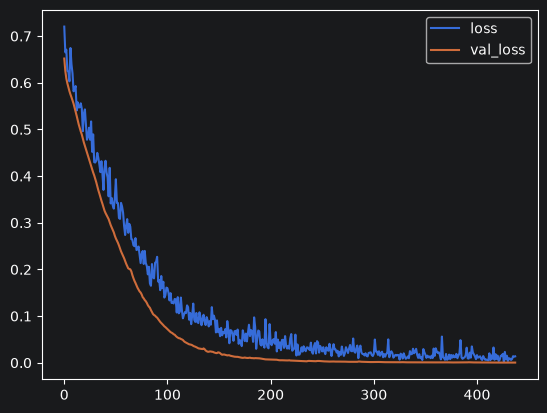

In [133]:
model_loss = pd.DataFrame(model.history.history)
model_loss.plot()

# 3. Evaluación del modelo

In [134]:
from sklearn.metrics import classification_report,confusion_matrix

## 3.1. Predicción sobre el conjunto de Test

In [137]:
#predictions = model.predict_classes(X_test)
predictions = (model.predict(X_test) > 0.5).astype("int32") #Si nueva versión de scikit-learn

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


In [138]:
# https://en.wikipedia.org/wiki/Precision_and_recall
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       140
           1       1.00      1.00      1.00        60

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [139]:
print(confusion_matrix(y_test,predictions))

[[140   0]
 [  0  60]]


## 3.2. Predicción sobre nuevos datos

In [144]:
# Lectura de datos a predecir
#df_pred = pd.read_excel('./german.data', sheet_name='Datos_Predecir')
df_pred = pd.read_csv('../data/raw/german.data', sep=r'\s+', header=None)


# Filtramos usando X_train.columns (ya que 'df' no está definido en el entorno)
# Nos aseguramos de mantener solo las columnas de interés del entrenamiento
features_cols = [col for col in X_train.columns if col in df_pred.columns]
df_pred = df_pred[features_cols]

# Eliminamos la columna objetivo (si viniera vacía en el Excel)
X_pred = df_pred.drop('target', axis=1, errors='ignore')

# Escalamos los datos (asumiendo que 'scaler' fue ajustado previamente con el entrenamiento)
X_pred_scaled = scaler.transform(X_pred)

# Realizamos la predicción (predict_classes está obsoleto; usamos predict + umbral de 0.5)
resultado_prob = model.predict(X_pred_scaled)
resultado_clases = (resultado_prob > 0.5).astype(int)

# Unimos la predicción al DataFrame de forma limpia usando .flatten()
df_pred['PREDICCIÓN'] = resultado_clases.flatten()

NameError: name 'scaler' is not defined

In [78]:
#Guardar y cargar el modelo para posterior uso
from tensorflow.keras.models import load_model
model.save('modelo_pred_binomial.h5')